In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, random, warnings, gc
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

DRIVE_DIR = Path('/content/drive/MyDrive')
INPUT_FILE = DRIVE_DIR / 'model_ready_category_dataset.csv'
OUT_DIR = DRIVE_DIR / 'model_3_stacked_lstm_rolling_origin_outputs'
OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_COL = 'weekly_quantity'
DATE_COL = 'week_start'
CATEGORY_COL = 'Product Category'
SEASONAL_PERIOD = 52
EPS = 1e-12

OUTER_ORIGINS = {
    'spring_2025': '2025-04-07',
    'summer_2025': '2025-07-07',
    'early_autumn_2025': '2025-09-08',
    'q4_year_end_2025': '2025-10-06',
}
FORECAST_HORIZONS = [4, 8, 12]
MAX_HORIZON = max(FORECAST_HORIZONS)
INNER_CV_HORIZON = 4
INNER_CV_OFFSETS_WEEKS = [12, 8, 4]

OPTIONAL_EXOGENOUS = ['transaction_count', 'active_customer_count']
EXOG_LAGS = [12, 26, 52]

print('TensorFlow:', tf.__version__)
print('Output directory:', OUT_DIR)

Mounted at /content/drive
TensorFlow: 2.20.0
Output directory: /content/drive/MyDrive/model_3_stacked_lstm_rolling_origin_outputs


In [2]:
if not INPUT_FILE.exists():
    raise FileNotFoundError(INPUT_FILE)

raw = pd.read_csv(INPUT_FILE)
raw[DATE_COL] = pd.to_datetime(raw[DATE_COL])
required = [CATEGORY_COL, DATE_COL, TARGET_COL]
missing = [c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f'Missing required columns: {missing}')

available_exog = [c for c in OPTIONAL_EXOGENOUS if c in raw.columns]
keep_cols = required + available_exog
raw = raw[keep_cols].copy()
raw = raw.dropna(subset=required).sort_values([CATEGORY_COL, DATE_COL])
if raw.duplicated([CATEGORY_COL, DATE_COL]).any():
    raise ValueError('Duplicate category-week observations detected.')

categories = sorted(raw[CATEGORY_COL].unique())
dataset_min, dataset_max = raw[DATE_COL].min(), raw[DATE_COL].max()
full_weeks = pd.date_range(dataset_min, dataset_max, freq='7D')

parts = []
for cat in categories:
    cols = [TARGET_COL] + available_exog
    x = raw[raw[CATEGORY_COL] == cat].set_index(DATE_COL)[cols].reindex(full_weeks)
    x.index.name = DATE_COL
    x[TARGET_COL] = x[TARGET_COL].fillna(0.0).clip(lower=0)
    for c in available_exog:
        x[c] = x[c].fillna(0.0).clip(lower=0)
    x[CATEGORY_COL] = cat
    parts.append(x.reset_index())

panel = pd.concat(parts, ignore_index=True).sort_values([CATEGORY_COL, DATE_COL]).reset_index(drop=True)

print('Shape:', panel.shape)
print('Categories:', len(categories))
print('Date range:', dataset_min.date(), 'to', dataset_max.date())
print('Optional operational variables found:', available_exog if available_exog else 'none')
if available_exog:
    print('lags:', EXOG_LAGS)
else:
    print('No operational covariates found')

Shape: (6200, 4)
Categories: 40
Date range: 2023-01-09 to 2025-12-22
Optional operational variables found: ['transaction_count']
lags: [12, 26, 52]


,scenario_id,outer_origin_label,outer_origin,horizon_weeks,test_start,test_end
0,spring_2025_h4,spring_2025,2025-04-07,4,2025-04-07,2025-04-28
1,spring_2025_h8,spring_2025,2025-04-07,8,2025-04-07,2025-05-26
2,spring_2025_h12,spring_2025,2025-04-07,12,2025-04-07,2025-06-23
3,summer_2025_h4,summer_2025,2025-07-07,4,2025-07-07,2025-07-28
4,summer_2025_h8,summer_2025,2025-07-07,8,2025-07-07,2025-08-25
5,summer_2025_h12,summer_2025,2025-07-07,12,2025-07-07,2025-09-22
6,early_autumn_2025_h4,early_autumn_2025,2025-09-08,4,2025-09-08,2025-09-29
7,early_autumn_2025_h8,early_autumn_2025,2025-09-08,8,2025-09-08,2025-10-27
8,early_autumn_2025_h12,early_autumn_2025,2025-09-08,12,2025-09-08,2025-11-24
9,q4_year_end_2025_h4,q4_year_end_2025,2025-10-06,4,2025-10-06,2025-10-27


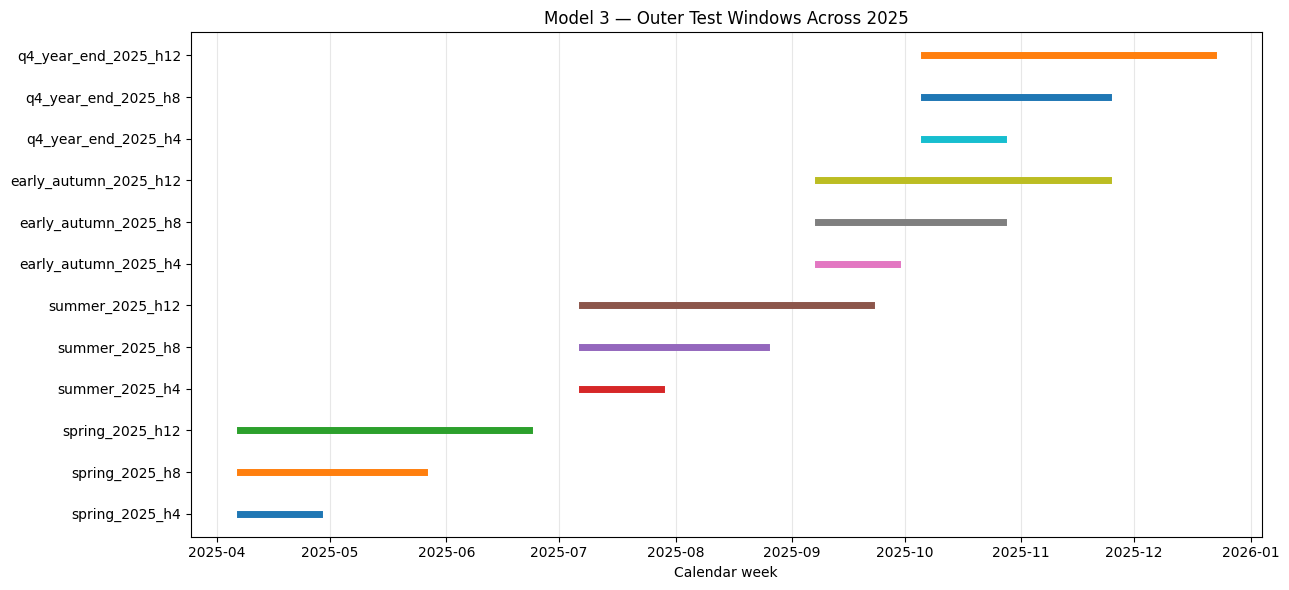

In [3]:
scenario_rows = []
for label, origin_s in OUTER_ORIGINS.items():
    origin = pd.Timestamp(origin_s)
    if origin not in full_weeks:
        raise ValueError(f'{origin} is not aligned with weekly calendar.')
    for h in FORECAST_HORIZONS:
        dates = pd.date_range(origin, periods=h, freq='7D')
        if dates[-1] > dataset_max:
            raise ValueError(f'{label}, h={h} exceeds dataset end.')
        scenario_rows.append({
            'scenario_id': f'{label}_h{h}', 'outer_origin_label': label,
            'outer_origin': origin, 'horizon_weeks': h,
            'test_start': dates[0], 'test_end': dates[-1]
        })
scenarios = pd.DataFrame(scenario_rows)
scenarios.to_csv(OUT_DIR/'model_3_common_rolling_origin_scenarios.csv', index=False, encoding='utf-8-sig')
display(scenarios)

plt.figure(figsize=(13,6))
for i,r in scenarios.iterrows():
    plt.plot([r.test_start,r.test_end],[i,i],linewidth=5)
plt.yticks(range(len(scenarios)),scenarios.scenario_id)
plt.title('Model 3 — Outer Test Windows Across 2025')
plt.xlabel('Calendar week'); plt.grid(axis='x',alpha=.3); plt.tight_layout()
plt.savefig(OUT_DIR/'plot_outer_test_windows.png',dpi=160); plt.show()

In [4]:
def mae(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float)
    return float(np.mean(np.abs(a-p)))

def rmse(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float)
    return float(np.sqrt(np.mean((a-p)**2)))

def mape(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float)
    mask=np.abs(a)>EPS
    return np.nan if mask.sum()==0 else float(np.mean(np.abs((a[mask]-p[mask])/a[mask]))*100)

def smape(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float)
    d=np.abs(a)+np.abs(p)
    return float(np.mean(np.where(d>EPS,2*np.abs(a-p)/d,0))*100)

def mase_scale_info(y_train,m=52):
    y=np.asarray(y_train,float)
    if len(y)<=m:
        return np.nan,'insufficient_history'
    scale=float(np.mean(np.abs(y[m:]-y[:-m])))
    if not np.isfinite(scale):
        return np.nan,'non_finite_scale'
    if scale<=EPS:
        return np.nan,'zero_seasonal_scale'
    return scale,'valid'

def evaluate(a,p,y_train,m=52):
    scale,status=mase_scale_info(y_train,m)
    return {
        'MAE':mae(a,p),'RMSE':rmse(a,p),'MAPE':mape(a,p),
        'MAPE_N':int(np.sum(np.abs(np.asarray(a,float))>EPS)),
        'sMAPE':smape(a,p),
        'MASE':np.nan if not np.isfinite(scale) else mae(a,p)/scale,
        'MASE_scale':scale,'MASE_status':status
    }

print('MASE: seasonal m=52')

MASE: seasonal m=52


In [5]:
def add_calendar_features(df):
    z=df.copy()
    iso=z[DATE_COL].dt.isocalendar()
    z['year']=z[DATE_COL].dt.year.astype(int)
    z['month']=z[DATE_COL].dt.month.astype(int)
    z['quarter']=z[DATE_COL].dt.quarter.astype(int)
    z['week_of_year']=iso.week.astype(int)
    z['week_sin']=np.sin(2*np.pi*z['week_of_year']/52.0)
    z['week_cos']=np.cos(2*np.pi*z['week_of_year']/52.0)
    z['month_sin']=np.sin(2*np.pi*z['month']/12.0)
    z['month_cos']=np.cos(2*np.pi*z['month']/12.0)
    return z

CALENDAR_FEATURES=['year','month','quarter','week_of_year','week_sin','week_cos','month_sin','month_cos']
EXOG_FEATURES=[f'{c}_lag_{lag}' for c in available_exog for lag in EXOG_LAGS]
SEQUENCE_FEATURES=[TARGET_COL]+CALENDAR_FEATURES+EXOG_FEATURES
CONTEXT_FEATURES=CALENDAR_FEATURES+EXOG_FEATURES

observed_lookup={}
for cat in categories:
    d=panel[panel[CATEGORY_COL]==cat].set_index(DATE_COL)
    observed_lookup[cat]={c:d[c].to_dict() for c in available_exog}

def exog_lag_values(cat,date):
    out={}
    date=pd.Timestamp(date)
    for c in available_exog:
        for lag in EXOG_LAGS:
            src=date-pd.Timedelta(weeks=lag)
            out[f'{c}_lag_{lag}']=float(observed_lookup[cat][c].get(src,0.0))
    return out

def make_row(cat,date,y_value):
    row={CATEGORY_COL:cat,DATE_COL:pd.Timestamp(date),TARGET_COL:float(y_value)}
    row.update(exog_lag_values(cat,date))
    z=add_calendar_features(pd.DataFrame([row]))
    return z.iloc[0].to_dict()

def feature_table_from_observed(df):
    rows=[]
    for _,r in df.iterrows():
        rows.append(make_row(r[CATEGORY_COL],r[DATE_COL],r[TARGET_COL]))
    return pd.DataFrame(rows).sort_values([CATEGORY_COL,DATE_COL]).reset_index(drop=True)

OBSERVED_FEATURE_TABLE = feature_table_from_observed(panel)

print('Sequence features:', SEQUENCE_FEATURES)
print('Forecast-date context features:', CONTEXT_FEATURES)
pd.DataFrame({'sequence_feature':pd.Series(SEQUENCE_FEATURES)}).to_csv(OUT_DIR/'model_3_sequence_features.csv',index=False)
pd.DataFrame({'context_feature':pd.Series(CONTEXT_FEATURES)}).to_csv(OUT_DIR/'model_3_context_features.csv',index=False)

Sequence features: ['weekly_quantity', 'year', 'month', 'quarter', 'week_of_year', 'week_sin', 'week_cos', 'month_sin', 'month_cos', 'transaction_count_lag_12', 'transaction_count_lag_26', 'transaction_count_lag_52']
Forecast-date context features: ['year', 'month', 'quarter', 'week_of_year', 'week_sin', 'week_cos', 'month_sin', 'month_cos', 'transaction_count_lag_12', 'transaction_count_lag_26', 'transaction_count_lag_52']


In [6]:
CANDIDATES = [
 {'lookback':12,'units1':64,'units2':32,'dropout':0.10,'lr':1e-3,'batch_size':32,'scaler':'standard','target_transform':'log1p','embedding_dim':4},
 {'lookback':12,'units1':64,'units2':32,'dropout':0.20,'lr':5e-4,'batch_size':32,'scaler':'standard','target_transform':'log1p','embedding_dim':4},
 {'lookback':12,'units1':96,'units2':48,'dropout':0.20,'lr':1e-3,'batch_size':32,'scaler':'standard','target_transform':'log1p','embedding_dim':8},
 {'lookback':12,'units1':128,'units2':64,'dropout':0.30,'lr':5e-4,'batch_size':32,'scaler':'standard','target_transform':'log1p','embedding_dim':8},
 {'lookback':26,'units1':64,'units2':32,'dropout':0.10,'lr':1e-3,'batch_size':32,'scaler':'standard','target_transform':'log1p','embedding_dim':4},
 {'lookback':26,'units1':96,'units2':48,'dropout':0.20,'lr':5e-4,'batch_size':32,'scaler':'standard','target_transform':'log1p','embedding_dim':8},
 {'lookback':26,'units1':128,'units2':64,'dropout':0.30,'lr':5e-4,'batch_size':64,'scaler':'standard','target_transform':'log1p','embedding_dim':8},
 {'lookback':26,'units1':64,'units2':32,'dropout':0.20,'lr':1e-3,'batch_size':32,'scaler':'minmax','target_transform':'log1p','embedding_dim':4},
 {'lookback':12,'units1':64,'units2':32,'dropout':0.20,'lr':1e-3,'batch_size':32,'scaler':'minmax','target_transform':'log1p','embedding_dim':4},
 {'lookback':12,'units1':96,'units2':48,'dropout':0.20,'lr':5e-4,'batch_size':32,'scaler':'standard','target_transform':'raw','embedding_dim':8},
 {'lookback':26,'units1':96,'units2':48,'dropout':0.20,'lr':5e-4,'batch_size':32,'scaler':'standard','target_transform':'raw','embedding_dim':8},
 {'lookback':26,'units1':128,'units2':64,'dropout':0.30,'lr':2e-4,'batch_size':64,'scaler':'standard','target_transform':'log1p','embedding_dim':8},
]
for i,c in enumerate(CANDIDATES,1):
    c['trial_id']=i
    c['config_id']=f'stacked_lstm_{i:02d}'

candidate_df=pd.DataFrame(CANDIDATES)
candidate_df.to_csv(OUT_DIR/'model_3_candidate_configurations.csv',index=False,encoding='utf-8-sig')
print('TOTAL STACKED-LSTM CANDIDATE CONFIGURATIONS:',len(CANDIDATES))
display(candidate_df)

TOTAL STACKED-LSTM CANDIDATE CONFIGURATIONS: 12


,lookback,units1,units2,dropout,lr,batch_size,scaler,target_transform,embedding_dim,trial_id,config_id
0,12,64,32,0.1,0.0010,32,standard,log1p,4,1,stacked_lstm_01
1,12,64,32,0.2,0.0005,32,standard,log1p,4,2,stacked_lstm_02
2,12,96,48,0.2,0.0010,32,standard,log1p,8,3,stacked_lstm_03
3,12,128,64,0.3,0.0005,32,standard,log1p,8,4,stacked_lstm_04
4,26,64,32,0.1,0.0010,32,standard,log1p,4,5,stacked_lstm_05
5,26,96,48,0.2,0.0005,32,standard,log1p,8,6,stacked_lstm_06
6,26,128,64,0.3,0.0005,64,standard,log1p,8,7,stacked_lstm_07
7,26,64,32,0.2,0.0010,32,minmax,log1p,4,8,stacked_lstm_08
8,12,64,32,0.2,0.0010,32,minmax,log1p,4,9,stacked_lstm_09
9,12,96,48,0.2,0.0005,32,standard,raw,8,10,stacked_lstm_10


In [7]:
def transform_target(y,method):
    y=np.asarray(y,float)
    return np.log1p(np.maximum(y,0)) if method=='log1p' else y

def inverse_target(y,method):
    y=np.asarray(y,float)
    return np.expm1(y) if method=='log1p' else y

def category_mapping_from_training(train_raw):
    cats=sorted(train_raw[CATEGORY_COL].unique())
    return {c:i for i,c in enumerate(cats)}

def make_scaler(name):
    return StandardScaler() if name=='standard' else MinMaxScaler()

def build_training_arrays(train_raw, config):
    cutoff=train_raw[DATE_COL].max()
    ft=OBSERVED_FEATURE_TABLE[OBSERVED_FEATURE_TABLE[DATE_COL]<=cutoff].copy()
    cmap=category_mapping_from_training(train_raw)
    lookback=int(config['lookback'])

    seq_scaler=make_scaler(config['scaler'])
    ctx_scaler=make_scaler(config['scaler'])
    seq_scaler.fit(ft[SEQUENCE_FEATURES].astype(float))
    if CONTEXT_FEATURES:
        ctx_scaler.fit(ft[CONTEXT_FEATURES].astype(float))

    Xseq,Xctx,Xcat,y,dates,cats=[],[],[],[],[],[]
    for cat in sorted(ft[CATEGORY_COL].unique()):
        d=ft[ft[CATEGORY_COL]==cat].sort_values(DATE_COL).reset_index(drop=True)
        seq_scaled=seq_scaler.transform(d[SEQUENCE_FEATURES].astype(float))
        ctx_scaled=(ctx_scaler.transform(d[CONTEXT_FEATURES].astype(float))
                    if CONTEXT_FEATURES else np.zeros((len(d),0)))
        vals=d[TARGET_COL].values.astype(float)
        for i in range(lookback,len(d)):
            Xseq.append(seq_scaled[i-lookback:i])
            Xctx.append(ctx_scaled[i])
            Xcat.append(cmap[cat])
            y.append(transform_target([vals[i]],config['target_transform'])[0])
            dates.append(pd.Timestamp(d.loc[i,DATE_COL])); cats.append(cat)

    return (np.asarray(Xseq,float),np.asarray(Xctx,float),np.asarray(Xcat,int),
            np.asarray(y,float),pd.DataFrame({'target_date':dates,CATEGORY_COL:cats}),
            seq_scaler,ctx_scaler,cmap,ft)

def build_model(config,n_seq_features,n_ctx_features,n_categories):
    seq_in=layers.Input(shape=(int(config['lookback']),n_seq_features),name='sequence')
    cat_in=layers.Input(shape=(),dtype='int32',name='category_id')
    emb=layers.Embedding(n_categories,int(config['embedding_dim']),name='category_embedding')(cat_in)
    emb=layers.Flatten()(emb)

    x=layers.LSTM(int(config['units1']),return_sequences=True,name='lstm_1')(seq_in)
    x=layers.Dropout(float(config['dropout']))(x)
    x=layers.LSTM(int(config['units2']),return_sequences=False,name='lstm_2')(x)
    x=layers.Dropout(float(config['dropout']))(x)

    inputs=[seq_in,cat_in]
    pieces=[x,emb]
    if n_ctx_features>0:
        ctx_in=layers.Input(shape=(n_ctx_features,),name='forecast_context')
        inputs.append(ctx_in); pieces.append(ctx_in)
    x=layers.Concatenate()(pieces)
    x=layers.Dense(32,activation='relu')(x)
    x=layers.Dropout(float(config['dropout'])/2)(x)
    out=layers.Dense(1,activation='linear')(x)
    model=Model(inputs=inputs,outputs=out)
    model.compile(optimizer=Adam(learning_rate=float(config['lr'])),loss='mae')
    return model

def fit_lstm(train_raw,config,verbose=0):
    tf.keras.backend.clear_session(); gc.collect()
    Xseq,Xctx,Xcat,y,meta,seq_scaler,ctx_scaler,cmap,ft=build_training_arrays(train_raw,config)
    if len(y)<20:
        raise ValueError('Too few supervised samples.')

    unique_dates=np.array(sorted(meta.target_date.unique()))
    n_val_dates=max(4,int(np.ceil(0.15*len(unique_dates))))
    cutoff=pd.Timestamp(unique_dates[-n_val_dates])
    tr=meta.target_date<cutoff
    va=meta.target_date>=cutoff
    if tr.sum()==0 or va.sum()==0:
        raise ValueError('Internal temporal split is empty.')

    model=build_model(config,Xseq.shape[2],Xctx.shape[1],len(cmap))
    tr_inputs=[Xseq[tr],Xcat[tr]] + ([Xctx[tr]] if Xctx.shape[1]>0 else [])
    va_inputs=[Xseq[va],Xcat[va]] + ([Xctx[va]] if Xctx.shape[1]>0 else [])
    callbacks=[
        EarlyStopping(monitor='val_loss',patience=6,restore_best_weights=True,min_delta=1e-4),
        ReduceLROnPlateau(monitor='val_loss',patience=3,factor=.5,min_lr=1e-5)
    ]
    hist=model.fit(tr_inputs,y[tr],validation_data=(va_inputs,y[va]),
                   epochs=60,batch_size=int(config['batch_size']),shuffle=False,
                   callbacks=callbacks,verbose=verbose)
    return model,seq_scaler,ctx_scaler,cmap,ft,hist,cutoff

In [8]:
def recursive_forecast(model,seq_scaler,ctx_scaler,cmap,history_raw,forecast_dates,config,origin):
    origin=pd.Timestamp(origin)
    outputs=[]
    working={}
    for cat in sorted(history_raw[CATEGORY_COL].unique()):
        d=history_raw[history_raw[CATEGORY_COL]==cat].sort_values(DATE_COL)
        working[cat]=[make_row(cat,r[DATE_COL],r[TARGET_COL]) for _,r in d.iterrows()]

    for date in pd.to_datetime(forecast_dates):
        for cat in sorted(working):
            rows=working[cat]
            lookback=int(config['lookback'])
            if len(rows)<lookback:
                raise ValueError(f'Insufficient lookback for {cat}')
            seq_df=pd.DataFrame(rows[-lookback:])
            Xseq=seq_scaler.transform(seq_df[SEQUENCE_FEATURES].astype(float))[None,:,:]

            ctx_row=make_row(cat,date,0.0)
            for lag in EXOG_LAGS:
                if available_exog:
                    assert pd.Timestamp(date)-pd.Timedelta(weeks=lag) < origin
            if CONTEXT_FEATURES:
                Xctx=ctx_scaler.transform(pd.DataFrame([ctx_row])[CONTEXT_FEATURES].astype(float))
            Xcat=np.asarray([cmap[cat]],dtype=int)
            inputs=[Xseq,Xcat]+([Xctx] if CONTEXT_FEATURES else [])
            pred_t=float(model.predict(inputs,verbose=0).reshape(-1)[0])
            pred=float(max(0.0,inverse_target([pred_t],config['target_transform'])[0]))
            outputs.append({CATEGORY_COL:cat,DATE_COL:pd.Timestamp(date),'y_pred':pred})
            working[cat].append(make_row(cat,date,pred))
    return pd.DataFrame(outputs)

def score_category_forecasts(pred_df,actual_df,history_raw):
    merged=actual_df[[CATEGORY_COL,DATE_COL,TARGET_COL]].merge(pred_df,on=[CATEGORY_COL,DATE_COL],how='left')
    if merged.y_pred.isna().any():
        raise ValueError('Missing predictions.')
    rows=[]
    for cat in categories:
        q=merged[merged[CATEGORY_COL]==cat].sort_values(DATE_COL)
        hist=history_raw[history_raw[CATEGORY_COL]==cat].sort_values(DATE_COL)[TARGET_COL].values
        met=evaluate(q[TARGET_COL].values,q.y_pred.values,hist,SEASONAL_PERIOD)
        rows.append({CATEGORY_COL:cat,**met})
    return pd.DataFrame(rows),merged

def inner_folds(outer_origin):
    ans=[]
    for fold,offset in enumerate(INNER_CV_OFFSETS_WEEKS,1):
        vo=pd.Timestamp(outer_origin)-pd.Timedelta(weeks=offset)
        dates=pd.date_range(vo,periods=INNER_CV_HORIZON,freq='7D')
        if dates[-1]>=pd.Timestamp(outer_origin):
            raise AssertionError('Inner fold overlaps outer test.')
        ans.append((fold,vo,dates))
    return ans

In [9]:
all_trials=[]
selected_configs=[]
training_logs=[]

for origin_label,origin_s in OUTER_ORIGINS.items():
    origin=pd.Timestamp(origin_s)
    print(); print('='*100)
    print('TUNING FOR OUTER ORIGIN:',origin_label,origin.date())
    print('='*100)

    for config in CANDIDATES:
        print(f"Trial {config['trial_id']:02d}/{len(CANDIDATES)} | {config['config_id']} | lb={config['lookback']} | {config['target_transform']}")
        for fold,validation_origin,vdates in inner_folds(origin):
            row={'outer_origin_label':origin_label,'outer_origin':origin,'trial_id':config['trial_id'],
                 'config_id':config['config_id'],'inner_fold':fold,'validation_origin':validation_origin,
                 'config':json.dumps(config)}
            try:
                train_raw=panel[panel[DATE_COL]<validation_origin].copy()
                actual=panel[panel[DATE_COL].isin(vdates)].copy()
                assert train_raw[DATE_COL].max()<actual[DATE_COL].min()
                assert actual[DATE_COL].max()<origin

                model,ss,cs,cmap,ft,hist,internal_cutoff=fit_lstm(train_raw,config,verbose=0)
                pred=recursive_forecast(model,ss,cs,cmap,train_raw,vdates,config,validation_origin)
                cat_scores,_=score_category_forecasts(pred,actual,train_raw)
                row.update({
                    'status':'ok','mean_MAE':cat_scores.MAE.mean(),'mean_RMSE':cat_scores.RMSE.mean(),
                    'mean_MAPE':cat_scores.MAPE.mean(),'mean_sMAPE':cat_scores.sMAPE.mean(),
                    'mean_MASE':cat_scores.MASE.mean(),'median_MASE':cat_scores.MASE.median(),
                    'valid_MASE_N':int(cat_scores.MASE.notna().sum()),
                    'epochs_run':len(hist.history['loss']),'best_val_loss':float(np.min(hist.history['val_loss'])),
                    'internal_validation_start':internal_cutoff
                })
                training_logs.append({**row})
            except Exception as e:
                row.update({'status':'failed','mean_MAE':np.nan,'mean_RMSE':np.nan,'mean_MAPE':np.nan,
                            'mean_sMAPE':np.nan,'mean_MASE':np.nan,'median_MASE':np.nan,
                            'valid_MASE_N':0,'error':str(e)})
            all_trials.append(row)
            pd.DataFrame(all_trials).to_csv(OUT_DIR/'model_3_inner_cv_all_trials.csv',index=False,encoding='utf-8-sig')
            tf.keras.backend.clear_session(); gc.collect()

    t=pd.DataFrame([x for x in all_trials if x['outer_origin_label']==origin_label])
    ok=t[t.status=='ok'].copy()
    summary=(ok.groupby(['trial_id','config_id','config'],as_index=False)
             .agg(cv_mean_MASE=('mean_MASE','mean'),cv_std_MASE=('mean_MASE','std'),
                  cv_mean_sMAPE=('mean_sMAPE','mean'),cv_mean_RMSE=('mean_RMSE','mean'),
                  cv_mean_MAE=('mean_MAE','mean'),successful_folds=('inner_fold','nunique')))
    eligible=summary[summary.successful_folds==len(INNER_CV_OFFSETS_WEEKS)].copy()
    if eligible.empty:
        raise RuntimeError(f'No configuration completed all folds for {origin_label}')
    if eligible.cv_mean_MASE.notna().any():
        ranked=eligible.sort_values(['cv_mean_MASE','cv_std_MASE','cv_mean_RMSE','cv_mean_MAE'],na_position='last')
        selection_metric='mean_category_MASE'; selection_score=float(ranked.iloc[0].cv_mean_MASE)
    else:
        ranked=eligible.sort_values(['cv_mean_sMAPE','cv_mean_RMSE','cv_mean_MAE'])
        selection_metric='mean_category_sMAPE_fallback'; selection_score=float(ranked.iloc[0].cv_mean_sMAPE)
    best=ranked.iloc[0]
    selected_configs.append({
        'outer_origin_label':origin_label,'outer_origin':origin,'trial_id':int(best.trial_id),
        'config_id':best.config_id,'config':best.config,'selection_metric':selection_metric,
        'selection_score':selection_score,'cv_mean_MASE':best.cv_mean_MASE,'cv_std_MASE':best.cv_std_MASE,
        'cv_mean_sMAPE':best.cv_mean_sMAPE,'cv_mean_RMSE':best.cv_mean_RMSE,'cv_mean_MAE':best.cv_mean_MAE
    })
    print('SELECTED:',best.config_id,'|',selection_metric,'=',selection_score)

trials_df=pd.DataFrame(all_trials)
selected_df=pd.DataFrame(selected_configs)
selected_df.to_csv(OUT_DIR/'model_3_selected_configurations.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(training_logs).to_csv(OUT_DIR/'model_3_training_logs.csv',index=False,encoding='utf-8-sig')
display(selected_df)


TUNING FOR OUTER ORIGIN: spring_2025 2025-04-07
Trial 01/12 | stacked_lstm_01 | lb=12 | log1p
Trial 02/12 | stacked_lstm_02 | lb=12 | log1p
Trial 03/12 | stacked_lstm_03 | lb=12 | log1p
Trial 04/12 | stacked_lstm_04 | lb=12 | log1p
Trial 05/12 | stacked_lstm_05 | lb=26 | log1p
Trial 06/12 | stacked_lstm_06 | lb=26 | log1p
Trial 07/12 | stacked_lstm_07 | lb=26 | log1p
Trial 08/12 | stacked_lstm_08 | lb=26 | log1p
Trial 09/12 | stacked_lstm_09 | lb=12 | log1p
Trial 10/12 | stacked_lstm_10 | lb=12 | raw
Trial 11/12 | stacked_lstm_11 | lb=26 | raw
Trial 12/12 | stacked_lstm_12 | lb=26 | log1p
SELECTED: stacked_lstm_06 | mean_category_MASE = 1.2030519394466075

TUNING FOR OUTER ORIGIN: summer_2025 2025-07-07
Trial 01/12 | stacked_lstm_01 | lb=12 | log1p
Trial 02/12 | stacked_lstm_02 | lb=12 | log1p
Trial 03/12 | stacked_lstm_03 | lb=12 | log1p
Trial 04/12 | stacked_lstm_04 | lb=12 | log1p
Trial 05/12 | stacked_lstm_05 | lb=26 | log1p
Trial 06/12 | stacked_lstm_06 | lb=26 | log1p
Trial 07/1

,outer_origin_label,outer_origin,trial_id,config_id,config,selection_metric,selection_score,cv_mean_MASE,cv_std_MASE,cv_mean_sMAPE,cv_mean_RMSE,cv_mean_MAE
0,spring_2025,2025-04-07,6,stacked_lstm_06,"{""lookback"": 26, ""units1"": 96, ""units2"": 48, ""...",mean_category_MASE,1.203052,1.203052,1.134048,130.165385,95.226051,83.538130
1,summer_2025,2025-07-07,11,stacked_lstm_11,"{""lookback"": 26, ""units1"": 96, ""units2"": 48, ""...",mean_category_MASE,0.497678,0.497678,0.234132,109.696306,51.489610,42.937547
2,early_autumn_2025,2025-09-08,7,stacked_lstm_07,"{""lookback"": 26, ""units1"": 128, ""units2"": 64, ...",mean_category_MASE,0.322457,0.322457,0.188985,125.031411,36.611006,27.975247
3,q4_year_end_2025,2025-10-06,8,stacked_lstm_08,"{""lookback"": 26, ""units1"": 64, ""units2"": 32, ""...",mean_category_MASE,0.990118,0.990118,1.122448,133.445970,79.759604,67.556643


,trial_id,config_id,mean_inner_MASE,std_inner_MASE,completed_folds
6,7,stacked_lstm_07,0.799781,0.841077,12
5,6,stacked_lstm_06,0.815416,0.858584,12
11,12,stacked_lstm_12,0.854799,1.030090,12
7,8,stacked_lstm_08,0.901956,0.961357,12
1,2,stacked_lstm_02,0.949217,1.019458,12
4,5,stacked_lstm_05,0.957856,0.928267,12
2,3,stacked_lstm_03,0.961106,1.095868,12
8,9,stacked_lstm_09,0.974834,0.995546,12
0,1,stacked_lstm_01,1.231439,1.610651,12
3,4,stacked_lstm_04,1.396481,1.913214,12


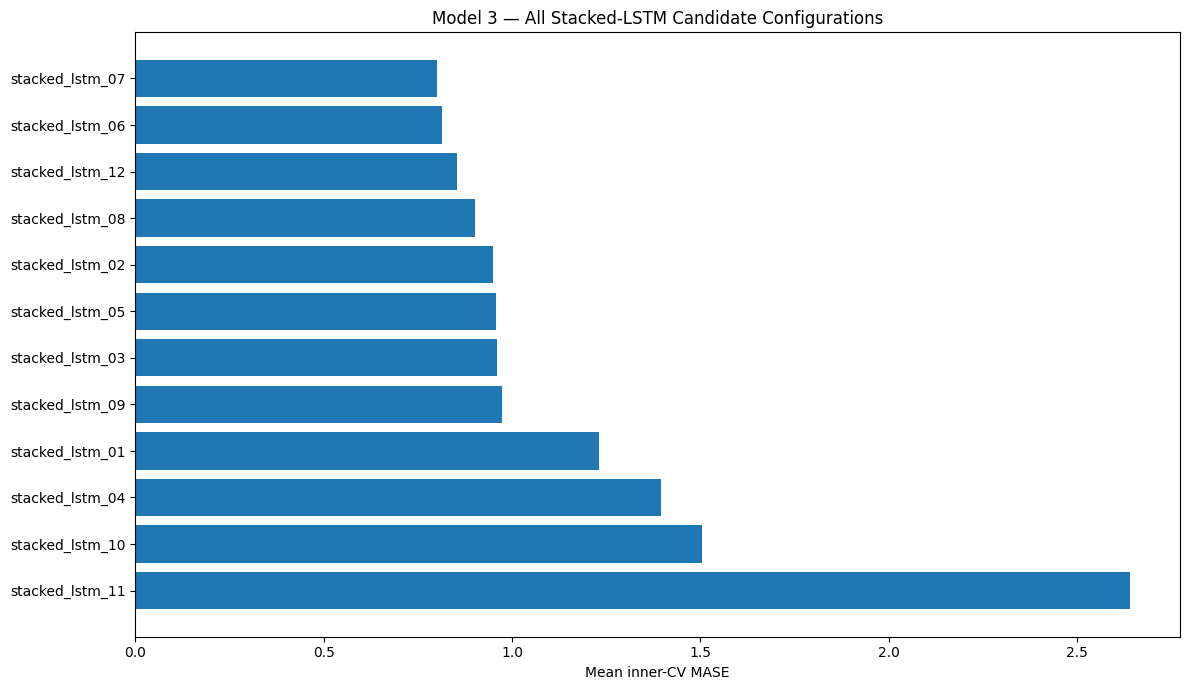

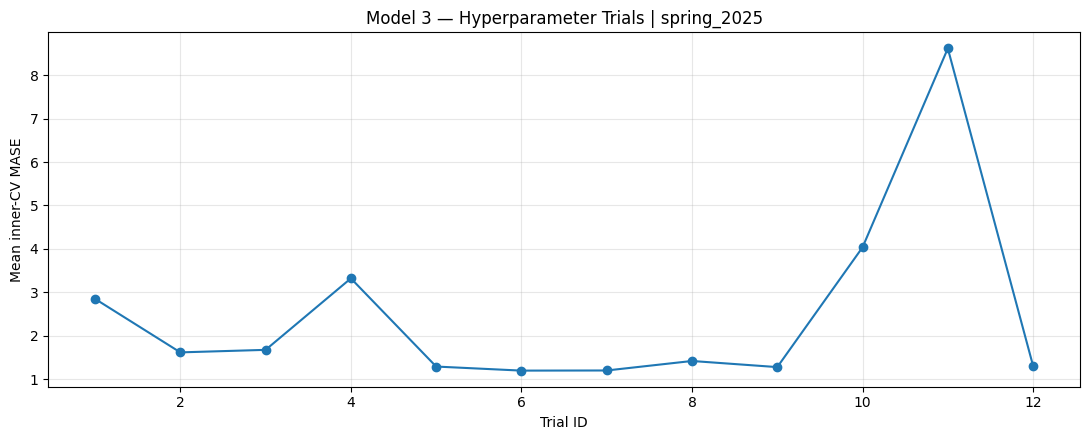

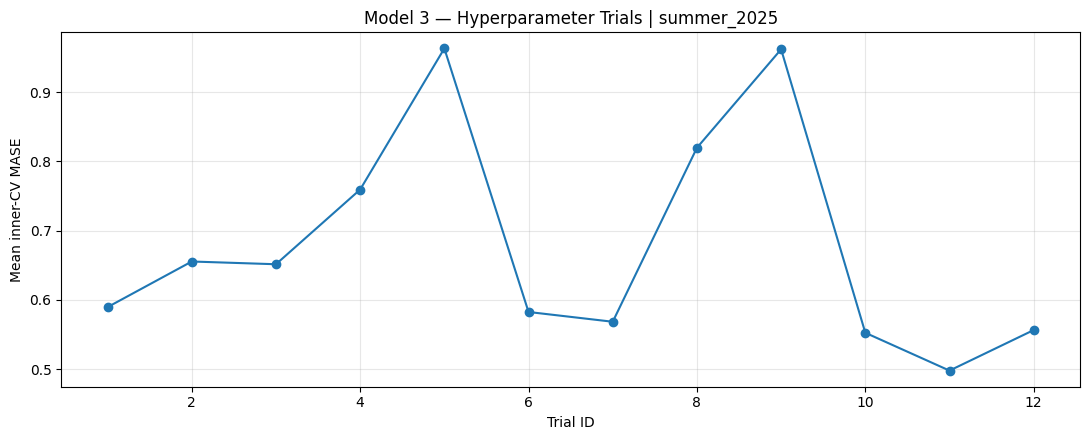

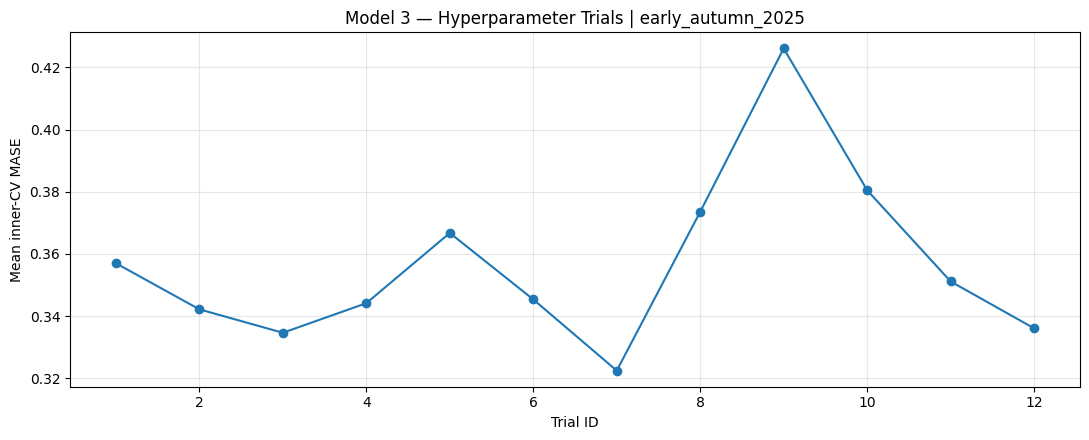

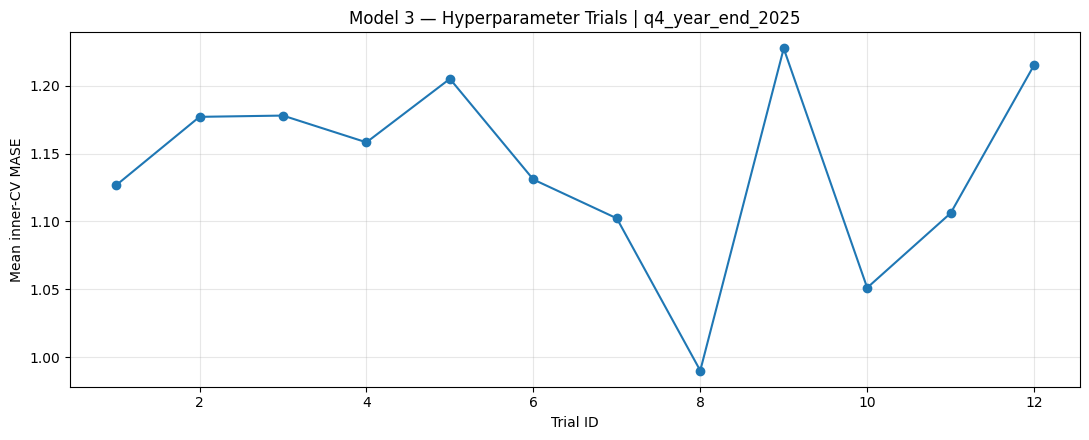

In [10]:
trial_summary=(trials_df[trials_df.status=='ok']
    .groupby(['trial_id','config_id'],as_index=False)
    .agg(mean_inner_MASE=('mean_MASE','mean'),std_inner_MASE=('mean_MASE','std'),completed_folds=('inner_fold','count'))
    .sort_values('mean_inner_MASE'))
trial_summary.to_csv(OUT_DIR/'model_3_all_candidate_performance.csv',index=False,encoding='utf-8-sig')
display(trial_summary)

plt.figure(figsize=(12,7))
plt.barh(trial_summary.config_id,trial_summary.mean_inner_MASE)
plt.gca().invert_yaxis(); plt.xlabel('Mean inner-CV MASE')
plt.title('Model 3 — All Stacked-LSTM Candidate Configurations')
plt.tight_layout(); plt.savefig(OUT_DIR/'plot_all_candidate_cv_mase.png',dpi=160); plt.show()

for label in OUTER_ORIGINS:
    q=trials_df[(trials_df.outer_origin_label==label)&(trials_df.status=='ok')]
    q=(q.groupby(['trial_id','config_id'],as_index=False).agg(mean_MASE=('mean_MASE','mean')).sort_values('trial_id'))
    plt.figure(figsize=(11,4.5)); plt.plot(q.trial_id,q.mean_MASE,marker='o')
    plt.xlabel('Trial ID'); plt.ylabel('Mean inner-CV MASE')
    plt.title(f'Model 3 — Hyperparameter Trials | {label}')
    plt.grid(alpha=.3); plt.tight_layout(); plt.savefig(OUT_DIR/f'plot_trials_{label}.png',dpi=160); plt.show()

In [11]:
outer_results=[]
outer_forecasts=[]
final_training_info=[]
trained={}

for _,sel in selected_df.iterrows():
    label=sel.outer_origin_label; origin=pd.Timestamp(sel.outer_origin); config=json.loads(sel.config)
    print(); print('='*100); print('OUTER TEST:',label,'| selected:',config['config_id']); print('='*100)
    train_raw=panel[panel[DATE_COL]<origin].copy()
    assert train_raw[DATE_COL].max()<origin

    model,ss,cs,cmap,ft,hist,internal_cutoff=fit_lstm(train_raw,config,verbose=0)
    trained[label]={'model':model,'seq_scaler':ss,'ctx_scaler':cs,'cmap':cmap,'config':config,'train_raw':train_raw}
    final_training_info.append({'outer_origin_label':label,'config_id':config['config_id'],
                                'epochs_run':len(hist.history['loss']),'best_val_loss':float(np.min(hist.history['val_loss'])),
                                'internal_validation_start':internal_cutoff})

    max_dates=pd.date_range(origin,periods=MAX_HORIZON,freq='7D')
    pred12=recursive_forecast(model,ss,cs,cmap,train_raw,max_dates,config,origin)
    for h in FORECAST_HORIZONS:
        dates=max_dates[:h]
        actual=panel[panel[DATE_COL].isin(dates)].copy()
        pred=pred12[pred12[DATE_COL].isin(dates)].copy()
        cat_scores,merged=score_category_forecasts(pred,actual,train_raw)
        sid=f'{label}_h{h}'
        for _,r in cat_scores.iterrows():
            outer_results.append({
                'scenario_id':sid,'outer_origin_label':label,'outer_origin':origin,'horizon_weeks':h,
                'test_start':dates[0],'test_end':dates[-1],CATEGORY_COL:r[CATEGORY_COL],
                'selected_config_id':config['config_id'],'selection_metric':sel.selection_metric,
                'cv_mean_MASE':sel.cv_mean_MASE,'cv_mean_sMAPE':sel.cv_mean_sMAPE,
                'MAE':r.MAE,'RMSE':r.RMSE,'MAPE':r.MAPE,'MAPE_N':r.MAPE_N,'sMAPE':r.sMAPE,
                'MASE':r.MASE,'MASE_scale':r.MASE_scale,'MASE_status':r.MASE_status
            })
        merged=merged.rename(columns={TARGET_COL:'y_true'})
        merged['scenario_id']=sid; merged['outer_origin_label']=label; merged['outer_origin']=origin
        merged['horizon_weeks']=h; merged['selected_config_id']=config['config_id']
        merged['absolute_error']=np.abs(merged.y_true-merged.y_pred)
        outer_forecasts.append(merged)

test_df=pd.DataFrame(outer_results)
forecasts_df=pd.concat(outer_forecasts,ignore_index=True)
test_df.to_csv(OUT_DIR/'model_3_outer_test_results.csv',index=False,encoding='utf-8-sig')
forecasts_df.to_csv(OUT_DIR/'model_3_outer_forecasts.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(final_training_info).to_csv(OUT_DIR/'model_3_final_training_info.csv',index=False,encoding='utf-8-sig')

print(); print('OUTER BACKTEST COMPLETE')
print('Category-level outer evaluations:',len(test_df))
print('Expected:',len(categories)*len(OUTER_ORIGINS)*len(FORECAST_HORIZONS))
print('Valid MASE:',test_df.MASE.notna().sum(),'| Undefined MASE:',test_df.MASE.isna().sum())


OUTER TEST: spring_2025 | selected: stacked_lstm_06

OUTER TEST: summer_2025 | selected: stacked_lstm_11

OUTER TEST: early_autumn_2025 | selected: stacked_lstm_07

OUTER TEST: q4_year_end_2025 | selected: stacked_lstm_08

OUTER BACKTEST COMPLETE
Category-level outer evaluations: 480
Expected: 480
Valid MASE: 468 | Undefined MASE: 12


SCENARIO SUMMARY


,scenario_id,outer_origin_label,horizon_weeks,MAE,RMSE,MAPE,sMAPE,MASE,median_MASE,valid_MASE_N
0,early_autumn_2025_h12,early_autumn_2025,12,637.127308,785.244738,3579.336178,100.743095,22.144035,0.509397,39
1,early_autumn_2025_h4,early_autumn_2025,4,287.921873,355.537807,130.824326,108.817956,3.543438,1.053152,39
2,early_autumn_2025_h8,early_autumn_2025,8,498.107613,672.187787,837.347058,101.767752,15.527306,0.664800,39
3,q4_year_end_2025_h12,q4_year_end_2025,12,31.876443,49.587810,98.467064,139.050767,0.493640,0.192133,39
4,q4_year_end_2025_h4,q4_year_end_2025,4,72.600875,80.117180,91.150511,180.216392,1.181586,0.336279,39
5,q4_year_end_2025_h8,q4_year_end_2025,8,43.012037,59.309974,96.690467,154.292690,0.674902,0.202178,39
6,spring_2025_h12,spring_2025,12,399.086237,457.625158,660.948913,97.346335,2.287115,0.320733,39
7,spring_2025_h4,spring_2025,4,235.497422,259.586129,186.241881,90.343929,1.699868,0.457938,39
8,spring_2025_h8,spring_2025,8,333.334267,390.887742,326.443504,96.141713,2.099758,0.421947,39
9,summer_2025_h12,summer_2025,12,69.830569,117.286594,141.174966,127.491061,0.964440,0.410405,39


OVERALL SUMMARY


,mean_MAE,mean_RMSE,mean_MAPE,mean_sMAPE,mean_MASE,median_MASE,valid_MASE_evaluations,undefined_MASE_evaluations,n_outer_evaluations
0,221.347881,274.832017,554.937168,120.459231,4.2646,0.290156,468,12,480


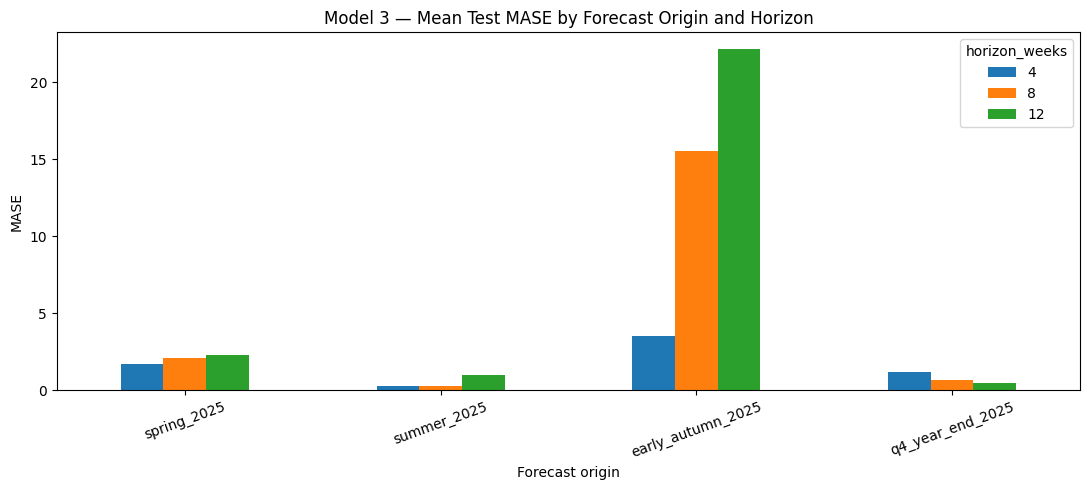

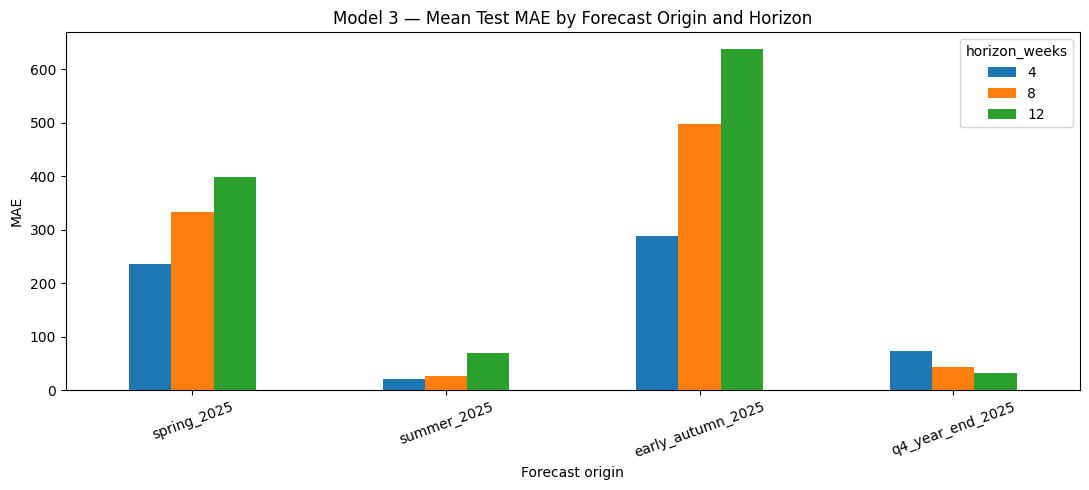

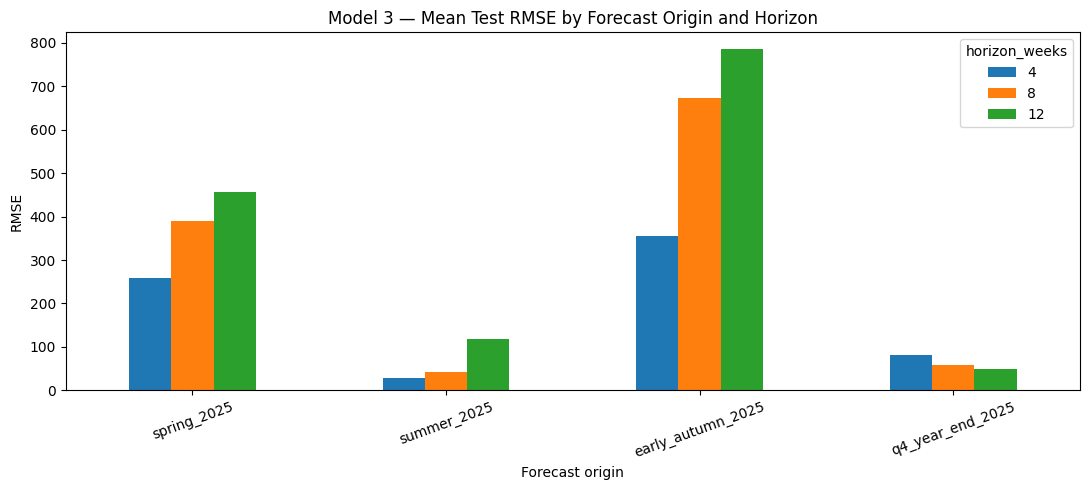

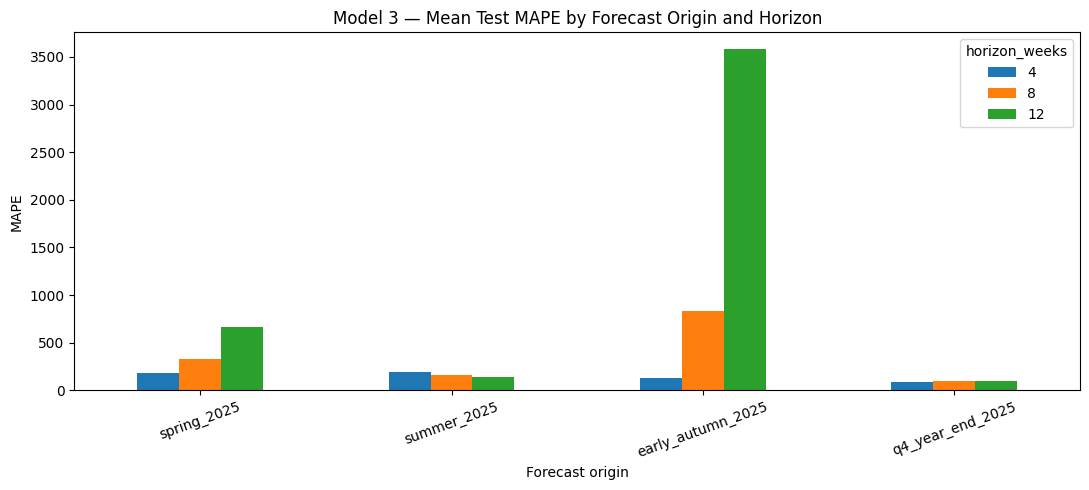

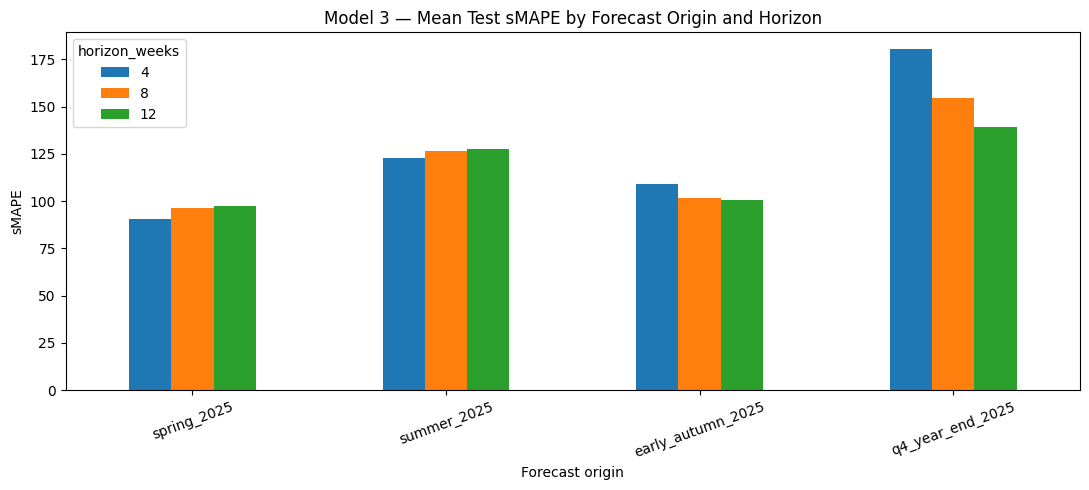

In [12]:
scenario_summary=(test_df.groupby(['scenario_id','outer_origin_label','horizon_weeks'],as_index=False)
    .agg(MAE=('MAE','mean'),RMSE=('RMSE','mean'),MAPE=('MAPE','mean'),sMAPE=('sMAPE','mean'),
         MASE=('MASE','mean'),median_MASE=('MASE','median'),valid_MASE_N=('MASE','count')))
overall_summary=pd.DataFrame([{
    'mean_MAE':test_df.MAE.mean(),'mean_RMSE':test_df.RMSE.mean(),'mean_MAPE':test_df.MAPE.mean(),
    'mean_sMAPE':test_df.sMAPE.mean(),'mean_MASE':test_df.MASE.mean(),'median_MASE':test_df.MASE.median(),
    'valid_MASE_evaluations':int(test_df.MASE.notna().sum()),'undefined_MASE_evaluations':int(test_df.MASE.isna().sum()),
    'n_outer_evaluations':len(test_df)
}])
scenario_summary.to_csv(OUT_DIR/'model_3_scenario_summary.csv',index=False,encoding='utf-8-sig')
overall_summary.to_csv(OUT_DIR/'model_3_overall_summary.csv',index=False,encoding='utf-8-sig')
print('SCENARIO SUMMARY'); display(scenario_summary)
print('OVERALL SUMMARY'); display(overall_summary)

for metric in ['MASE','MAE','RMSE','MAPE','sMAPE']:
    piv=scenario_summary.pivot(index='outer_origin_label',columns='horizon_weeks',values=metric).reindex(OUTER_ORIGINS.keys())
    ax=piv.plot(kind='bar',figsize=(11,5))
    ax.set_title(f'Model 3 — Mean Test {metric} by Forecast Origin and Horizon')
    ax.set_xlabel('Forecast origin'); ax.set_ylabel(metric); plt.xticks(rotation=20); plt.tight_layout()
    plt.savefig(OUT_DIR/f'plot_test_{metric.lower()}_by_origin_horizon.png',dpi=160); plt.show()

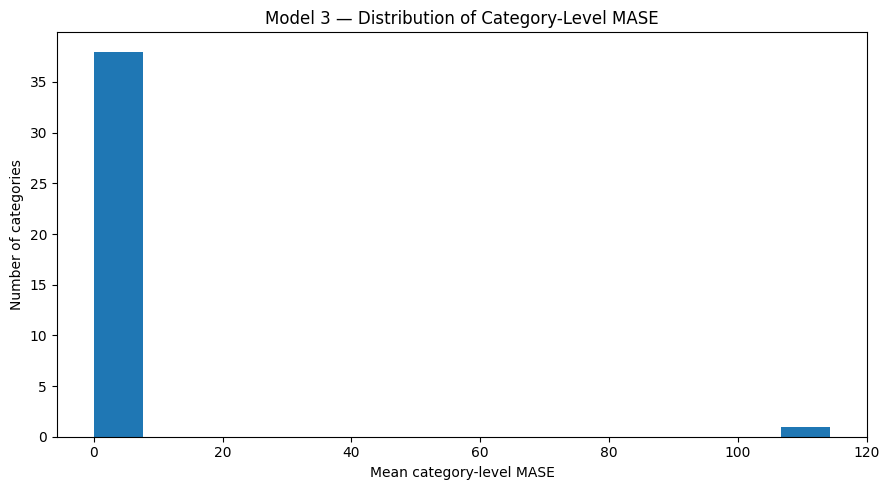

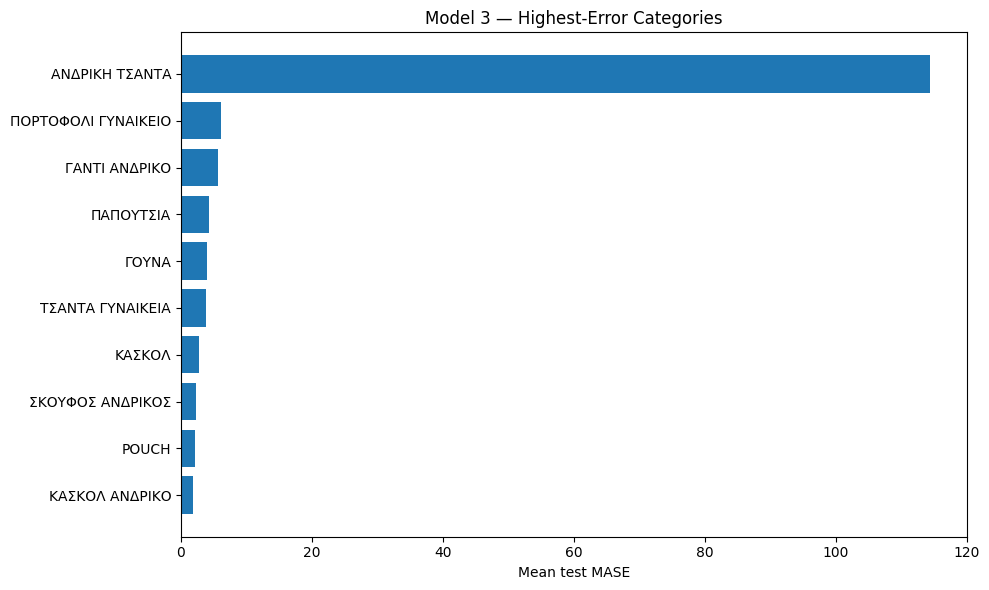

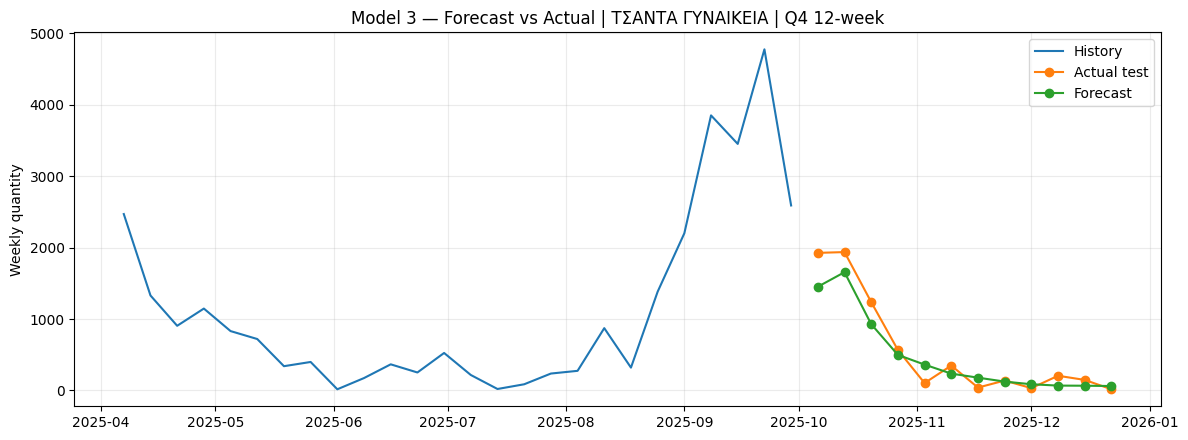

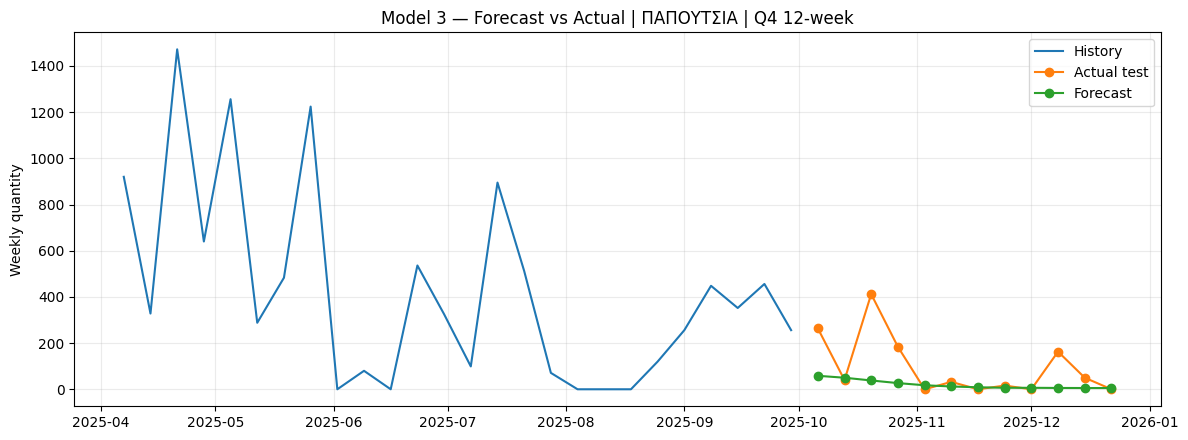

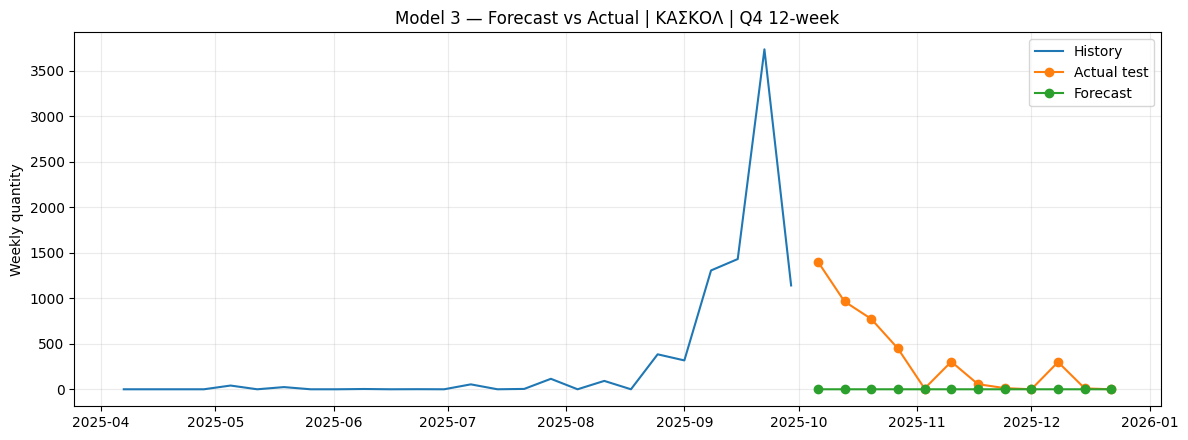

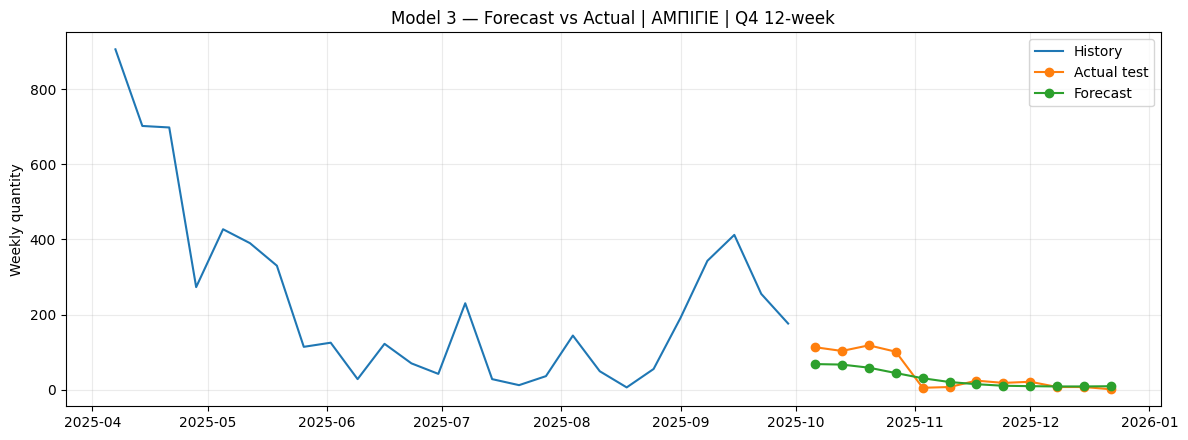

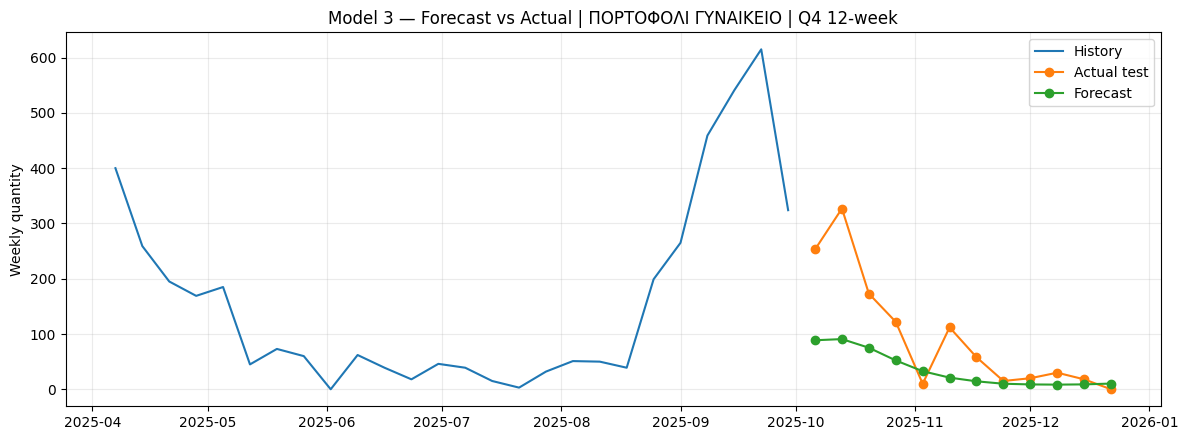

In [13]:
category_summary=(test_df.groupby(CATEGORY_COL,as_index=False)
                  .agg(mean_MASE=('MASE','mean'),median_MASE=('MASE','median'),mean_MAE=('MAE','mean'),mean_RMSE=('RMSE','mean'))
                  .sort_values('mean_MASE',ascending=False))
category_summary.to_csv(OUT_DIR/'model_3_category_error_summary.csv',index=False,encoding='utf-8-sig')

plt.figure(figsize=(9,5)); plt.hist(category_summary.mean_MASE.dropna(),bins=15)
plt.xlabel('Mean category-level MASE'); plt.ylabel('Number of categories')
plt.title('Model 3 — Distribution of Category-Level MASE')
plt.tight_layout(); plt.savefig(OUT_DIR/'plot_category_mase_distribution.png',dpi=160); plt.show()

worst=category_summary.head(10).sort_values('mean_MASE')
plt.figure(figsize=(10,6)); plt.barh(worst[CATEGORY_COL],worst.mean_MASE)
plt.xlabel('Mean test MASE'); plt.title('Model 3 — Highest-Error Categories')
plt.tight_layout(); plt.savefig(OUT_DIR/'plot_worst_categories.png',dpi=160); plt.show()

top_cats=(panel.groupby(CATEGORY_COL)[TARGET_COL].sum().sort_values(ascending=False).head(5).index.tolist())
for cat in top_cats:
    fc=forecasts_df[(forecasts_df[CATEGORY_COL]==cat)&(forecasts_df.scenario_id=='q4_year_end_2025_h12')].sort_values(DATE_COL)
    hist=panel[(panel[CATEGORY_COL]==cat)&(panel[DATE_COL]<pd.Timestamp(OUTER_ORIGINS['q4_year_end_2025']))].tail(26)
    if fc.empty: continue
    plt.figure(figsize=(12,4.5)); plt.plot(hist[DATE_COL],hist[TARGET_COL],label='History')
    plt.plot(fc[DATE_COL],fc.y_true,marker='o',label='Actual test'); plt.plot(fc[DATE_COL],fc.y_pred,marker='o',label='Forecast')
    plt.title(f'Model 3 — Forecast vs Actual | {cat} | Q4 12-week')
    plt.ylabel('Weekly quantity'); plt.legend(); plt.grid(alpha=.25); plt.tight_layout()
    safe=str(cat).replace('/','_').replace(' ','_')
    plt.savefig(OUT_DIR/f'plot_forecast_{safe}.png',dpi=160); plt.show()

,outer_origin_label,config_id,cv_mean_MASE,test_mean_MASE,test_minus_cv_MASE
0,spring_2025,stacked_lstm_06,1.203052,2.028914,0.825862
1,summer_2025,stacked_lstm_11,0.497678,0.507852,0.010174
2,early_autumn_2025,stacked_lstm_07,0.322457,13.738260,13.415802
3,q4_year_end_2025,stacked_lstm_08,0.990118,0.783376,-0.206742


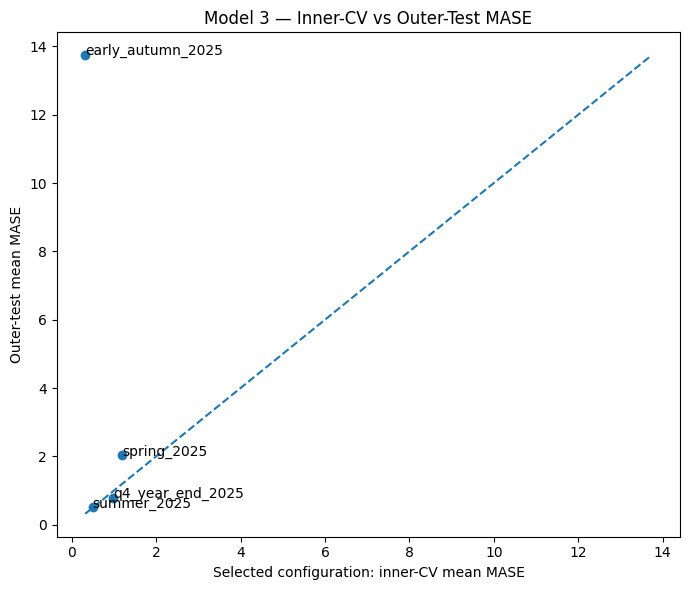

In [14]:
origin_test=(test_df.groupby('outer_origin_label',as_index=False).agg(test_mean_MASE=('MASE','mean')))
stability=selected_df[['outer_origin_label','config_id','cv_mean_MASE']].merge(origin_test,on='outer_origin_label')
stability['test_minus_cv_MASE']=stability.test_mean_MASE-stability.cv_mean_MASE
stability.to_csv(OUT_DIR/'model_3_cv_test_stability.csv',index=False,encoding='utf-8-sig')
display(stability)

plt.figure(figsize=(7,6)); plt.scatter(stability.cv_mean_MASE,stability.test_mean_MASE)
for _,r in stability.iterrows():
    plt.annotate(r.outer_origin_label,(r.cv_mean_MASE,r.test_mean_MASE))
lo=min(stability.cv_mean_MASE.min(),stability.test_mean_MASE.min())
hi=max(stability.cv_mean_MASE.max(),stability.test_mean_MASE.max())
plt.plot([lo,hi],[lo,hi],linestyle='--')
plt.xlabel('Selected configuration: inner-CV mean MASE'); plt.ylabel('Outer-test mean MASE')
plt.title('Model 3 — Inner-CV vs Outer-Test MASE')
plt.tight_layout(); plt.savefig(OUT_DIR/'plot_cv_vs_test_mase.png',dpi=160); plt.show()

In [15]:
prior_candidates={
 'Model 1 Statistical':[
   DRIVE_DIR/'model_1_rolling_origin_outputs'/'model_1_outer_test_results.csv',
   DRIVE_DIR/'model_1_statistical_baseline_outputs'/'model_1_outer_test_results.csv'],
 'Model 2 Tree-Based':[
   DRIVE_DIR/'model_2_tree_based_rolling_origin_outputs'/'model_2_outer_test_results.csv']
}
frames=[]
for name,paths in prior_candidates.items():
    found=next((p for p in paths if p.exists()),None)
    if found is not None:
        d=pd.read_csv(found); d['model']=name; frames.append(d[['model','MASE','MAE','RMSE','MAPE','sMAPE']])
        print('Loaded:',name,found)
    else:
        print('Comparison skipped for',name,'— result file not found.')
m3=test_df.copy(); m3['model']='Model 3 Stacked LSTM'; frames.append(m3[['model','MASE','MAE','RMSE','MAPE','sMAPE']])
comparison=pd.concat(frames,ignore_index=True)
comparison_summary=comparison.groupby('model',as_index=False).agg(MASE=('MASE','mean'),MAE=('MAE','mean'),RMSE=('RMSE','mean'),MAPE=('MAPE','mean'),sMAPE=('sMAPE','mean'))
comparison_summary.to_csv(OUT_DIR/'model_3_comparison_available_models.csv',index=False,encoding='utf-8-sig')
display(comparison_summary)

Loaded: Model 1 Statistical /content/drive/MyDrive/model_1_rolling_origin_outputs/model_1_outer_test_results.csv
Loaded: Model 2 Tree-Based /content/drive/MyDrive/model_2_tree_based_rolling_origin_outputs/model_2_outer_test_results.csv


,model,MASE,MAE,RMSE,MAPE,sMAPE
0,Model 1 Statistical,1.031349,72.885009,88.827605,215.011254,81.804379
1,Model 2 Tree-Based,1.266963,63.757185,86.548685,101.949450,130.535167
2,Model 3 Stacked LSTM,4.264600,221.347881,274.832017,554.937168,120.459231


In [16]:
audit=[]
audit.append({'check':'all inner validation windows end before outer origin',
              'passed':all(dates[-1]<pd.Timestamp(OUTER_ORIGINS[label]) for label in OUTER_ORIGINS for _,_,dates in inner_folds(pd.Timestamp(OUTER_ORIGINS[label])))})
audit.append({'check':'outer tests start at declared origins',
              'passed':bool((scenarios.test_start==scenarios.outer_origin).all())})
audit.append({'check':'expected category x origin x horizon evaluations',
              'passed':len(test_df)==len(categories)*len(OUTER_ORIGINS)*len(FORECAST_HORIZONS)})
audit.append({'check':'same-week operational variables excluded from model inputs',
              'passed':not any(c in SEQUENCE_FEATURES+CONTEXT_FEATURES for c in OPTIONAL_EXOGENOUS)})
audit.append({'check':'all operational covariate lags are >= maximum forecast horizon',
              'passed':all(lag>=MAX_HORIZON for lag in EXOG_LAGS)})
audit.append({'check':'valid MASE rows have positive finite seasonal scale',
              'passed':bool(((test_df.loc[test_df.MASE_status=='valid','MASE_scale']>0)&np.isfinite(test_df.loc[test_df.MASE_status=='valid','MASE_scale'])).all())})
audit.append({'check':'undefined MASE rows remain NaN',
              'passed':bool(test_df.loc[test_df.MASE_status!='valid','MASE'].isna().all())})
audit.append({'check':'no missing forecasts', 'passed':bool(forecasts_df.y_pred.notna().all())})
audit.append({'check':'no negative forecasts', 'passed':bool((forecasts_df.y_pred>=0).all())})
audit_df=pd.DataFrame(audit)
audit_df.to_csv(OUT_DIR/'model_3_integrity_audit.csv',index=False,encoding='utf-8-sig')
display(audit_df)
if not audit_df.passed.all():
    raise AssertionError('One or more integrity checks failed.')

print(); print('MODEL 3')
print('Outer evaluations:',len(test_df))
print('Valid MASE:',test_df.MASE.notna().sum(),'| Undefined:',test_df.MASE.isna().sum())
print('Mean MASE:',test_df.MASE.mean())
print('Median MASE:',test_df.MASE.median())
print('Mean MAE:',test_df.MAE.mean())
print('Mean RMSE:',test_df.RMSE.mean())
print('Mean MAPE:',test_df.MAPE.mean())
print('Mean sMAPE:',test_df.sMAPE.mean())
print('All outputs saved to:',OUT_DIR)

,check,passed
0,all inner validation windows end before outer ...,True
1,outer tests start at declared origins,True
2,expected category x origin x horizon evaluations,True
3,same-week operational variables excluded from ...,True
4,all operational covariate lags are >= maximum ...,True
5,valid MASE rows have positive finite seasonal ...,True
6,undefined MASE rows remain NaN,True
7,no missing forecasts,True
8,no negative forecasts,True



MODEL 3
Outer evaluations: 480
Valid MASE: 468 | Undefined: 12
Mean MASE: 4.264600308605377
Median MASE: 0.2901563913792132
Mean MAE: 221.34788127359423
Mean RMSE: 274.8320172122678
Mean MAPE: 554.9371675868805
Mean sMAPE: 120.4592311242754
All outputs saved to: /content/drive/MyDrive/model_3_stacked_lstm_rolling_origin_outputs
